# Day 035 | Mini Project: SPT Borehole Data EDA
## 100 Days of ML for Geotechnical Engineering
**Phase:** Data Science Essentials

**Author:** Ripon Chandra Malo  
**Date:** 2026

---

## Phase 2 Capstone -- Full EDA Pipeline

This is the capstone project for Phase 2. We will apply **every skill learned** to a
real multi-borehole SPT dataset: loading, cleaning, exploratory data analysis, feature engineering,
preprocessing, and dimensionality reduction.

| Step | Technique | What We Look For |
|------|-----------|------------------|
| **Load** | `pd.read_csv` | Shape, dtypes, first rows |
| **Clean** | Missing values, duplicates, outliers | Data quality issues |
| **EDA** | Distributions, correlations, group stats | Patterns in SPT data |
| **Feature Engineering** | Domain-based new features | N1_60, soil class, depth bins |
| **Preprocessing** | Scaling, encoding | ML-ready numerical matrix |
| **PCA** | Dimensionality reduction | Compress correlated features |
| **Summary** | Key findings | What we learned from the data |

---

## The Dataset

We have SPT (Standard Penetration Test) data from **6 boreholes** across a construction site:
- 150 samples with 12 columns
- Features: borehole ID, coordinates, depth, N-value, soil type, water content, unit weight,
  fines content, Atterberg limits, and measured shear wave velocity

**Goal:** Explore this dataset thoroughly and prepare it for ML modeling.

---

## Part 1: Load and Inspect

The first step in any data project: load the data and understand what we have.

---

In [1]:
# ─────────────────────────────────────────────────────
# STEP 1: LOAD THE SPT BOREHOLE DATASET
# ─────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ── Load data ──
df = pd.read_csv("spt_site_data.csv")

print("SPT Borehole Dataset — First Look")
print("=" * 55)
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"\nColumns: {list(df.columns)}")
print(f"\nData types:")
print(df.dtypes)
print(f"\nFirst 5 rows:")
df.head()

SPT Borehole Dataset — First Look
Shape: 150 rows x 12 columns

Columns: ['borehole_id', 'x_coord', 'y_coord', 'depth', 'N_value', 'soil_type', 'water_content', 'unit_weight', 'fines_content', 'liquid_limit', 'plasticity_index', 'Vs_measured']

Data types:
borehole_id             str
x_coord               int64
y_coord               int64
depth               float64
N_value               int64
soil_type               str
water_content       float64
unit_weight         float64
fines_content       float64
liquid_limit        float64
plasticity_index    float64
Vs_measured         float64
dtype: object

First 5 rows:


,borehole_id,x_coord,y_coord,depth,N_value,soil_type,water_content,unit_weight,fines_content,liquid_limit,plasticity_index,Vs_measured
0,BH-01,100,200,1.9,11,Silt,25.7,18.44,61.2,33.2,20.4,209.0
1,BH-01,100,200,2.2,27,Silty Sand,16.6,19.22,23.6,0.0,0.0,255.0
2,BH-01,100,200,3.7,31,Sand,5.0,20.24,0.4,0.0,0.0,290.4
3,BH-01,100,200,4.7,13,Silty Clay,30.5,18.23,60.7,39.2,21.9,200.7
4,BH-01,100,200,6.0,12,Silt,22.4,18.35,51.8,25.7,12.9,216.9


In [2]:
# ─────────────────────────────────────────────────────
# QUICK STATISTICS
# ─────────────────────────────────────────────────────
print("Descriptive Statistics")
print("=" * 55)
print(df.describe().round(2))
print()

# ── Categorical summaries ──
print("Borehole Distribution:")
print(df['borehole_id'].value_counts().sort_index())
print()
print("Soil Type Distribution:")
print(df['soil_type'].value_counts())

Descriptive Statistics
       x_coord  y_coord   depth  N_value  water_content  unit_weight  \
count   150.00   150.00  150.00   150.00         150.00       150.00   
mean    166.67   216.67   15.71    28.42          22.19        18.51   
std      50.39    48.70    8.25    10.31          10.44         1.09   
min     100.00   150.00    1.50    10.00           5.00        16.30   
25%     120.00   180.00    8.82    20.00          13.20        17.64   
50%     165.00   210.00   16.05    29.00          21.45        18.69   
75%     200.00   250.00   23.22    36.00          31.12        19.32   
max     250.00   300.00   29.40    51.00          44.90        20.86   

       fines_content  liquid_limit  plasticity_index  Vs_measured  
count         150.00        150.00            150.00       150.00  
mean           42.75         22.64             13.74       274.61  
std            29.60         19.22             13.13        37.89  
min             0.00          0.00              0.00    

## Part 2: Data Cleaning

Even carefully collected geotechnical data has issues. We check for:
- Missing values
- Duplicate rows
- Invalid ranges (negative N-values? unrealistic unit weights?)
- Outliers using the IQR method

---

In [3]:
# ─────────────────────────────────────────────────────
# CHECK FOR MISSING VALUES
# ─────────────────────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(1)

print("Missing Value Report")
print("=" * 55)
missing_report = pd.DataFrame({
    'Missing': missing,
    'Percent': missing_pct
})
print(missing_report)
print(f"\nTotal missing values: {missing.sum()}")

if missing.sum() == 0:
    print("Dataset is complete — no missing values!")
else:
    print("Some columns have missing data — will need imputation.")

Missing Value Report
                  Missing  Percent
borehole_id             0      0.0
x_coord                 0      0.0
y_coord                 0      0.0
depth                   0      0.0
N_value                 0      0.0
soil_type               0      0.0
water_content           0      0.0
unit_weight             0      0.0
fines_content           0      0.0
liquid_limit            0      0.0
plasticity_index        0      0.0
Vs_measured             0      0.0

Total missing values: 0
Dataset is complete — no missing values!


In [4]:
# ─────────────────────────────────────────────────────
# CHECK FOR DUPLICATES AND INVALID RANGES
# ─────────────────────────────────────────────────────
print("Duplicate and Validity Checks")
print("=" * 55)

# ── Duplicates ──
n_dupes = df.duplicated().sum()
print(f"Duplicate rows: {n_dupes}")
if n_dupes > 0:
    df = df.drop_duplicates()
    print(f"  Removed {n_dupes} duplicates. New shape: {df.shape}")

# ── Physical validity checks ──
print(f"\nPhysical Range Checks:")
print(f"  N_value range: [{df['N_value'].min()}, {df['N_value'].max()}]  (expected: 0-100)")
print(f"  Depth range: [{df['depth'].min()}, {df['depth'].max()}] m  (expected: >0)")
print(f"  Unit weight: [{df['unit_weight'].min():.1f}, {df['unit_weight'].max():.1f}] kN/m3  (expected: 14-24)")
print(f"  Water content: [{df['water_content'].min():.1f}, {df['water_content'].max():.1f}] %  (expected: 0-80)")
print(f"  Fines content: [{df['fines_content'].min():.1f}, {df['fines_content'].max():.1f}] %  (expected: 0-100)")

# ── Flag physically unreasonable values ──
invalid_n = (df['N_value'] < 0).sum()
invalid_depth = (df['depth'] <= 0).sum()
invalid_uw = ((df['unit_weight'] < 14) | (df['unit_weight'] > 24)).sum()
print(f"\n  Invalid N_values (< 0): {invalid_n}")
print(f"  Invalid depths (<= 0): {invalid_depth}")
print(f"  Unusual unit weights (outside 14-24): {invalid_uw}")

Duplicate and Validity Checks
Duplicate rows: 0

Physical Range Checks:
  N_value range: [10, 51]  (expected: 0-100)
  Depth range: [1.5, 29.4] m  (expected: >0)
  Unit weight: [16.3, 20.9] kN/m3  (expected: 14-24)
  Water content: [5.0, 44.9] %  (expected: 0-80)
  Fines content: [0.0, 100.0] %  (expected: 0-100)

  Invalid N_values (< 0): 0
  Invalid depths (<= 0): 0
  Unusual unit weights (outside 14-24): 0


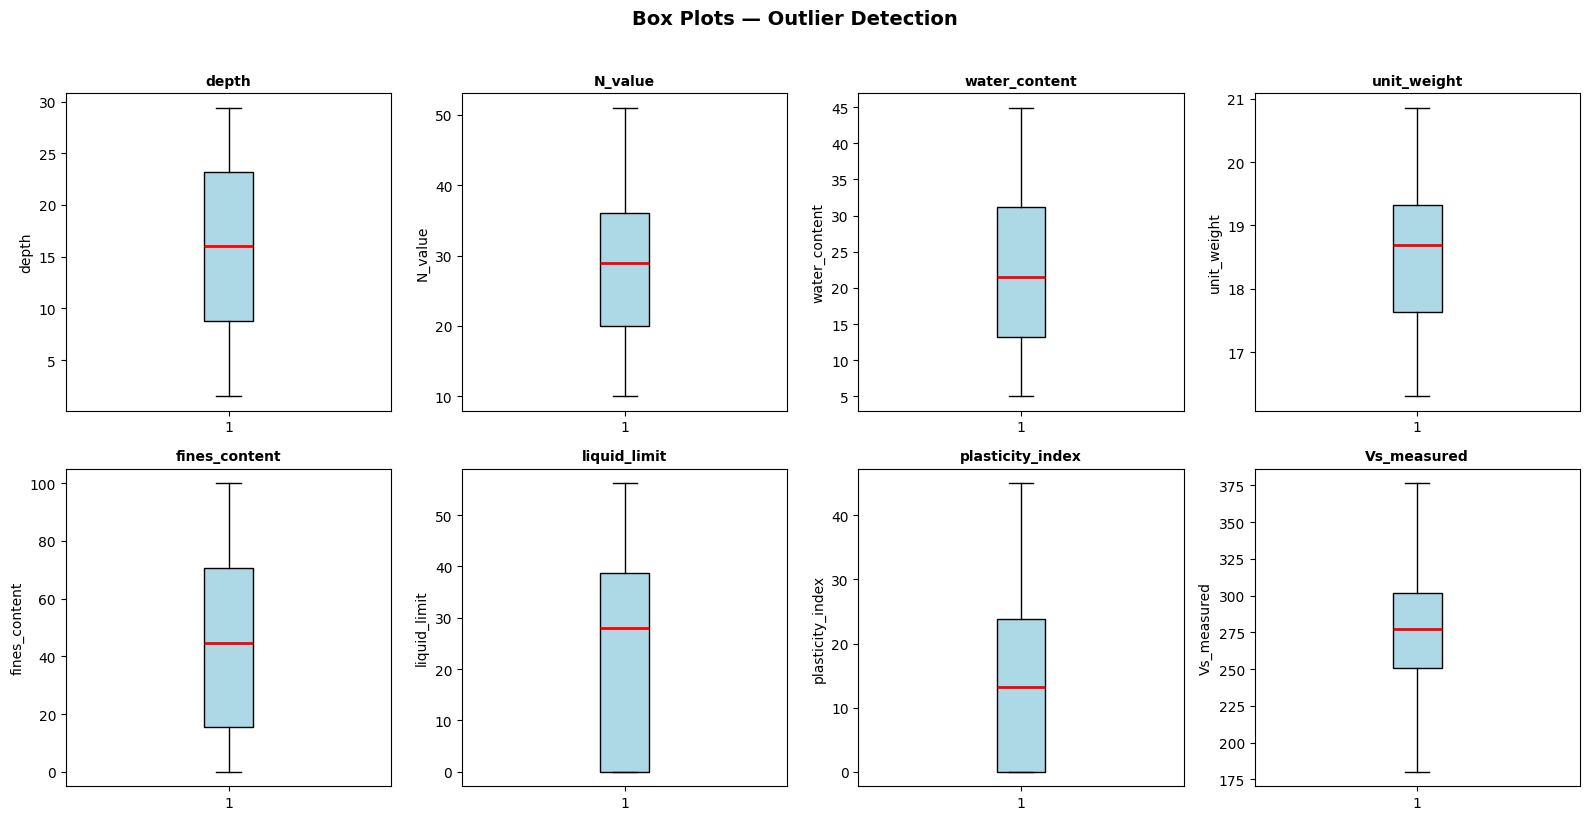

IQR-Based Outlier Count:
----------------------------------------
  depth               : 0 outliers
  N_value             : 0 outliers
  water_content       : 0 outliers
  unit_weight         : 0 outliers
  fines_content       : 0 outliers
  liquid_limit        : 0 outliers
  plasticity_index    : 0 outliers
  Vs_measured         : 0 outliers


In [5]:
# ─────────────────────────────────────────────────────
# OUTLIER DETECTION — Box plots for key features
# ─────────────────────────────────────────────────────
num_features = ['depth', 'N_value', 'water_content', 'unit_weight',
                'fines_content', 'liquid_limit', 'plasticity_index', 'Vs_measured']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.ravel(), num_features):
    ax.boxplot(df[col].dropna(), vert=True, patch_artist=True,
               boxprops=dict(facecolor='lightblue', edgecolor='black'),
               medianprops=dict(color='red', linewidth=2))
    ax.set_title(col, fontweight='bold', fontsize=10)
    ax.set_ylabel(col)

plt.suptitle('Box Plots — Outlier Detection', fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('boxplots_outliers.png', dpi=100, bbox_inches='tight')
plt.show()

# ── Count IQR-based outliers ──
print("IQR-Based Outlier Count:")
print("-" * 40)
for col in num_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    n_outliers = ((df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)).sum()
    print(f"  {col:20s}: {n_outliers} outliers")

## Part 3: Exploratory Data Analysis (EDA)

Now the fun part. Let us explore the data visually and statistically to discover patterns.

---

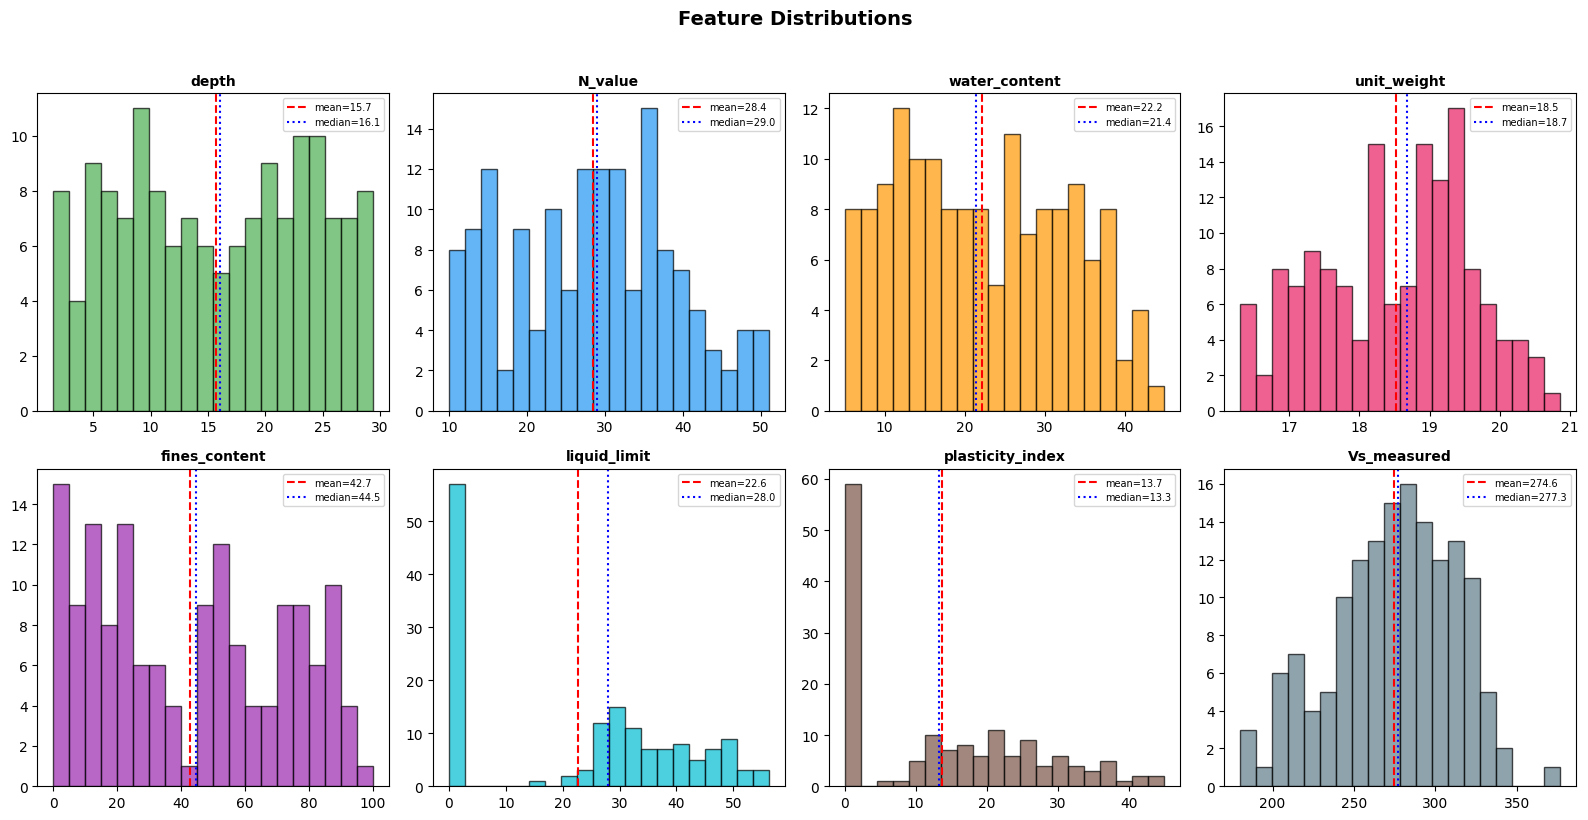

Observations:
  - N_value: right-skewed (most samples have low-moderate blow counts)
  - Water content: varies by soil type
  - Liquid limit: bimodal — non-plastic soils cluster near 0


In [6]:
# ─────────────────────────────────────────────────────
# DISTRIBUTION OF KEY FEATURES
# ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
colors = ['#4CAF50', '#2196F3', '#FF9800', '#E91E63',
          '#9C27B0', '#00BCD4', '#795548', '#607D8B']

for ax, col, color in zip(axes.ravel(), num_features, colors):
    ax.hist(df[col].dropna(), bins=20, color=color, edgecolor='black', alpha=0.7)
    ax.axvline(df[col].mean(), color='red', linestyle='--', linewidth=1.5,
               label=f'mean={df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='blue', linestyle=':', linewidth=1.5,
               label=f'median={df[col].median():.1f}')
    ax.set_title(col, fontweight='bold', fontsize=10)
    ax.legend(fontsize=7)

plt.suptitle('Feature Distributions', fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=100, bbox_inches='tight')
plt.show()

print("Observations:")
print("  - N_value: right-skewed (most samples have low-moderate blow counts)")
print("  - Water content: varies by soil type")
print("  - Liquid limit: bimodal — non-plastic soils cluster near 0")

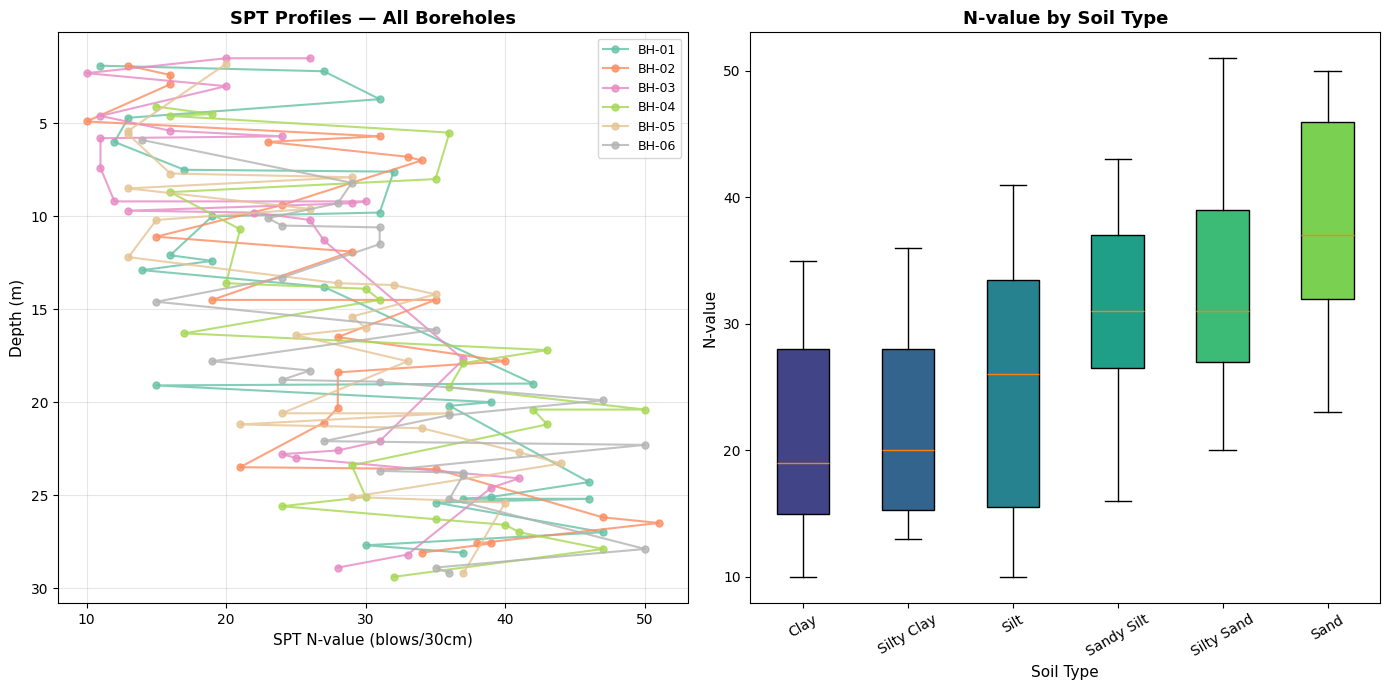

Key Patterns:
  - N-value generally increases with depth (soil gets denser)
  - Sand and Silty Sand have higher N-values than Clay and Silt
  - Each borehole shows a unique profile reflecting local stratigraphy


In [7]:
# ─────────────────────────────────────────────────────
# N-VALUE vs DEPTH — The classic SPT profile
# ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# ── All boreholes combined ──
ax = axes[0]
bh_colors = plt.cm.Set2(np.linspace(0, 1, df['borehole_id'].nunique()))
bh_map = dict(zip(sorted(df['borehole_id'].unique()), bh_colors))

for bh_id in sorted(df['borehole_id'].unique()):
    bh_data = df[df['borehole_id'] == bh_id].sort_values('depth')
    ax.plot(bh_data['N_value'], bh_data['depth'], 'o-',
            color=bh_map[bh_id], label=bh_id, markersize=5, alpha=0.8)

ax.set_xlabel('SPT N-value (blows/30cm)', fontsize=11)
ax.set_ylabel('Depth (m)', fontsize=11)
ax.invert_yaxis()
ax.set_title('SPT Profiles — All Boreholes', fontweight='bold', fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# ── N-value by soil type ──
ax = axes[1]
soil_order = df.groupby('soil_type')['N_value'].median().sort_values().index
soil_data = [df[df['soil_type'] == s]['N_value'].values for s in soil_order]
bp = ax.boxplot(soil_data, labels=soil_order, patch_artist=True, vert=True)
box_colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(soil_order)))
for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
ax.set_xlabel('Soil Type', fontsize=11)
ax.set_ylabel('N-value', fontsize=11)
ax.set_title('N-value by Soil Type', fontweight='bold', fontsize=13)
ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('spt_profiles.png', dpi=100, bbox_inches='tight')
plt.show()

print("Key Patterns:")
print("  - N-value generally increases with depth (soil gets denser)")
print("  - Sand and Silty Sand have higher N-values than Clay and Silt")
print("  - Each borehole shows a unique profile reflecting local stratigraphy")

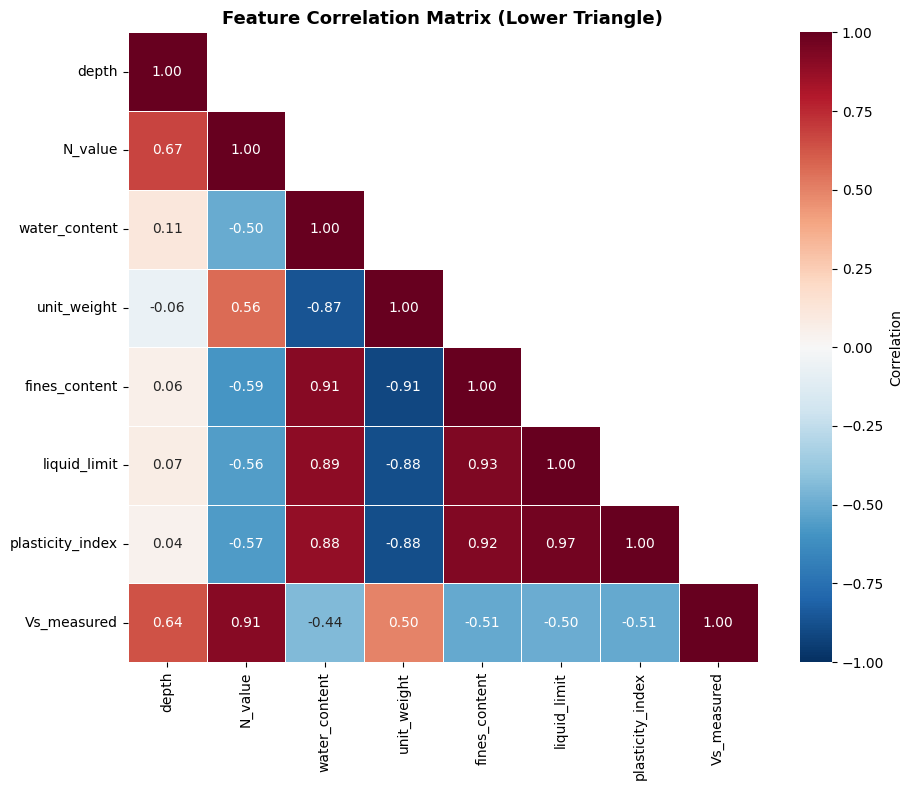

Strong Correlations (|r| > 0.5):
-------------------------------------------------------
  depth                <-> N_value               r = +0.674
  depth                <-> Vs_measured           r = +0.639
  N_value              <-> water_content         r = -0.504
  N_value              <-> unit_weight           r = +0.564
  N_value              <-> fines_content         r = -0.593
  N_value              <-> liquid_limit          r = -0.562
  N_value              <-> plasticity_index      r = -0.568
  N_value              <-> Vs_measured           r = +0.908
  water_content        <-> unit_weight           r = -0.866
  water_content        <-> fines_content         r = +0.906
  water_content        <-> liquid_limit          r = +0.891
  water_content        <-> plasticity_index      r = +0.880
  unit_weight          <-> fines_content         r = -0.911
  unit_weight          <-> liquid_limit          r = -0.885
  unit_weight          <-> plasticity_index      r = -0.883
  fines_con

In [8]:
# ─────────────────────────────────────────────────────
# CORRELATION ANALYSIS
# ─────────────────────────────────────────────────────
corr_cols = ['depth', 'N_value', 'water_content', 'unit_weight',
             'fines_content', 'liquid_limit', 'plasticity_index', 'Vs_measured']
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Correlation'})
ax.set_title('Feature Correlation Matrix (Lower Triangle)', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=100, bbox_inches='tight')
plt.show()

# ── Print strong correlations ──
print("Strong Correlations (|r| > 0.5):")
print("-" * 55)
for i in range(len(corr_cols)):
    for j in range(i + 1, len(corr_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.5:
            print(f"  {corr_cols[i]:20s} <-> {corr_cols[j]:20s}  r = {r:+.3f}")

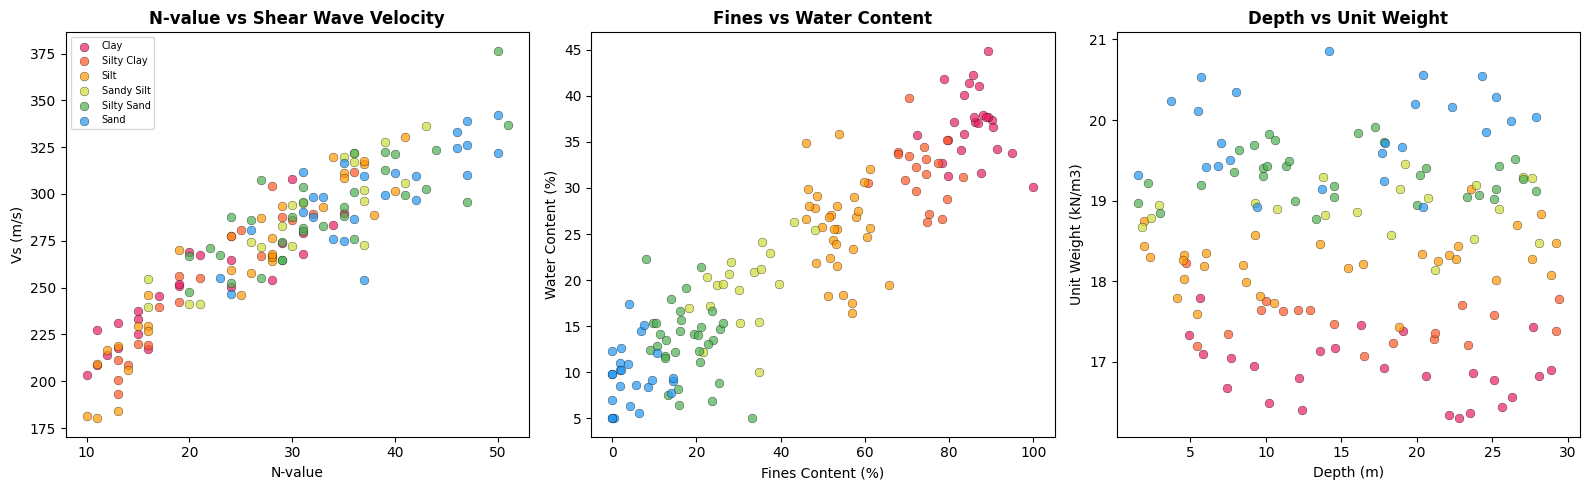

Key Relationships:
  - N-value and Vs are positively correlated (both measure stiffness)
  - Higher fines content leads to higher water content (clay holds more water)
  - Deeper soils tend to have higher unit weight (overburden compaction)


In [9]:
# ─────────────────────────────────────────────────────
# SCATTER PLOTS — Key relationships
# ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

soil_colors = {'Clay': '#E91E63', 'Silty Clay': '#FF5722', 'Silt': '#FF9800',
               'Sandy Silt': '#CDDC39', 'Silty Sand': '#4CAF50', 'Sand': '#2196F3'}

# ── N-value vs Vs_measured ──
ax = axes[0]
for soil in soil_colors:
    mask = df['soil_type'] == soil
    if mask.sum() > 0:
        ax.scatter(df.loc[mask, 'N_value'], df.loc[mask, 'Vs_measured'],
                   c=soil_colors[soil], label=soil, s=40, alpha=0.7,
                   edgecolors='black', linewidth=0.3)
ax.set_xlabel('N-value')
ax.set_ylabel('Vs (m/s)')
ax.set_title('N-value vs Shear Wave Velocity', fontweight='bold')
ax.legend(fontsize=7)

# ── Fines content vs Water content ──
ax = axes[1]
for soil in soil_colors:
    mask = df['soil_type'] == soil
    if mask.sum() > 0:
        ax.scatter(df.loc[mask, 'fines_content'], df.loc[mask, 'water_content'],
                   c=soil_colors[soil], label=soil, s=40, alpha=0.7,
                   edgecolors='black', linewidth=0.3)
ax.set_xlabel('Fines Content (%)')
ax.set_ylabel('Water Content (%)')
ax.set_title('Fines vs Water Content', fontweight='bold')

# ── Depth vs Unit Weight ──
ax = axes[2]
for soil in soil_colors:
    mask = df['soil_type'] == soil
    if mask.sum() > 0:
        ax.scatter(df.loc[mask, 'depth'], df.loc[mask, 'unit_weight'],
                   c=soil_colors[soil], label=soil, s=40, alpha=0.7,
                   edgecolors='black', linewidth=0.3)
ax.set_xlabel('Depth (m)')
ax.set_ylabel('Unit Weight (kN/m3)')
ax.set_title('Depth vs Unit Weight', fontweight='bold')

plt.tight_layout()
plt.savefig('scatter_relationships.png', dpi=100, bbox_inches='tight')
plt.show()

print("Key Relationships:")
print("  - N-value and Vs are positively correlated (both measure stiffness)")
print("  - Higher fines content leads to higher water content (clay holds more water)")
print("  - Deeper soils tend to have higher unit weight (overburden compaction)")

In [10]:
# ─────────────────────────────────────────────────────
# GROUP STATISTICS — By soil type and borehole
# ─────────────────────────────────────────────────────
print("Mean Properties by Soil Type")
print("=" * 70)
soil_stats = df.groupby('soil_type')[['N_value', 'water_content', 'unit_weight',
                                      'fines_content', 'Vs_measured']].mean().round(1)
print(soil_stats)
print()

print("Mean Properties by Borehole")
print("=" * 70)
bh_stats = df.groupby('borehole_id')[['depth', 'N_value', 'water_content',
                                       'Vs_measured']].agg(['mean', 'std']).round(1)
print(bh_stats)
print()

print("Observations:")
print("  - Sands have the highest N-values and Vs — they are the stiffest")
print("  - Clays have the highest water content and lowest unit weight")
print("  - Borehole-to-borehole variability shows spatial heterogeneity")

Mean Properties by Soil Type
            N_value  water_content  unit_weight  fines_content  Vs_measured
soil_type                                                                  
Clay           20.7           36.9         16.9           85.8        250.0
Sand           37.7            9.6         19.9            4.8        300.1
Sandy Silt     30.9           19.4         18.9           31.3        287.7
Silt           24.6           25.7         18.3           53.7        260.7
Silty Clay     21.9           31.7         17.5           73.4        252.3
Silty Sand     33.1           13.4         19.3           17.6        292.2

Mean Properties by Borehole
            depth      N_value       water_content       Vs_measured      
             mean  std    mean   std          mean   std        mean   std
borehole_id                                                               
BH-01        15.6  8.9    28.7  11.7          20.7  10.3       275.5  43.2
BH-02        15.0  8.9    28.6  10

## Part 4: Feature Engineering

Raw SPT data becomes more useful when we create geotechnically meaningful features.

---

In [11]:
# ─────────────────────────────────────────────────────
# FEATURE ENGINEERING — Domain knowledge features
# ─────────────────────────────────────────────────────

# ── 1. Overburden-corrected N-value (N1_60) ──
# Simplified correction: N1_60 = N * sqrt(100 / sigma_v')
# Using sigma_v' approx = unit_weight * depth (simplified, no water table)
df['sigma_v'] = df['unit_weight'] * df['depth']  # kPa (approximate)
df['N1_60'] = df['N_value'] * np.sqrt(100 / df['sigma_v'].clip(lower=1))
df['N1_60'] = df['N1_60'].clip(upper=100)  # cap unrealistic values

# ── 2. N-value per unit depth (penetration resistance gradient) ──
df['N_over_depth'] = df['N_value'] / df['depth']

# ── 3. Depth bins (shallow / medium / deep) ──
df['depth_category'] = pd.cut(df['depth'],
                               bins=[0, 5, 15, 50],
                               labels=['Shallow (0-5m)', 'Medium (5-15m)', 'Deep (>15m)'])

# ── 4. Soil class (coarse vs fine) ──
df['soil_class'] = df['fines_content'].apply(
    lambda fc: 'Fine-grained' if fc > 50 else 'Coarse-grained'
)

# ── 5. Activity (plasticity_index / clay fraction estimate) ──
df['activity'] = np.where(
    df['fines_content'] > 10,
    df['plasticity_index'] / df['fines_content'] * 100,
    0
)

print("Engineered Features")
print("=" * 55)
print(f"New columns: N1_60, N_over_depth, depth_category, soil_class, activity")
print(f"Total columns: {df.shape[1]}")
print()
print(df[['borehole_id', 'depth', 'N_value', 'N1_60', 'N_over_depth',
          'depth_category', 'soil_class']].head(10))

Engineered Features
New columns: N1_60, N_over_depth, depth_category, soil_class, activity
Total columns: 18

  borehole_id  depth  N_value      N1_60  N_over_depth  depth_category  \
0       BH-01    1.9       11  18.583839      5.789474  Shallow (0-5m)   
1       BH-01    2.2       27  41.521758     12.272727  Shallow (0-5m)   
2       BH-01    3.7       31  35.822474      8.378378  Shallow (0-5m)   
3       BH-01    4.7       13  14.044332      2.765957  Shallow (0-5m)   
4       BH-01    6.0       12  11.436354      2.000000  Medium (5-15m)   
5       BH-01    7.5       17  14.907120      2.266667  Medium (5-15m)   
6       BH-01    7.6       32  26.279346      4.210526  Medium (5-15m)   
7       BH-01    9.8       31  22.534998      3.163265  Medium (5-15m)   
8       BH-01   10.0       19  14.261146      1.900000  Medium (5-15m)   
9       BH-01   12.1       16  10.951611      1.322314  Medium (5-15m)   

       soil_class  
0    Fine-grained  
1  Coarse-grained  
2  Coarse-grain

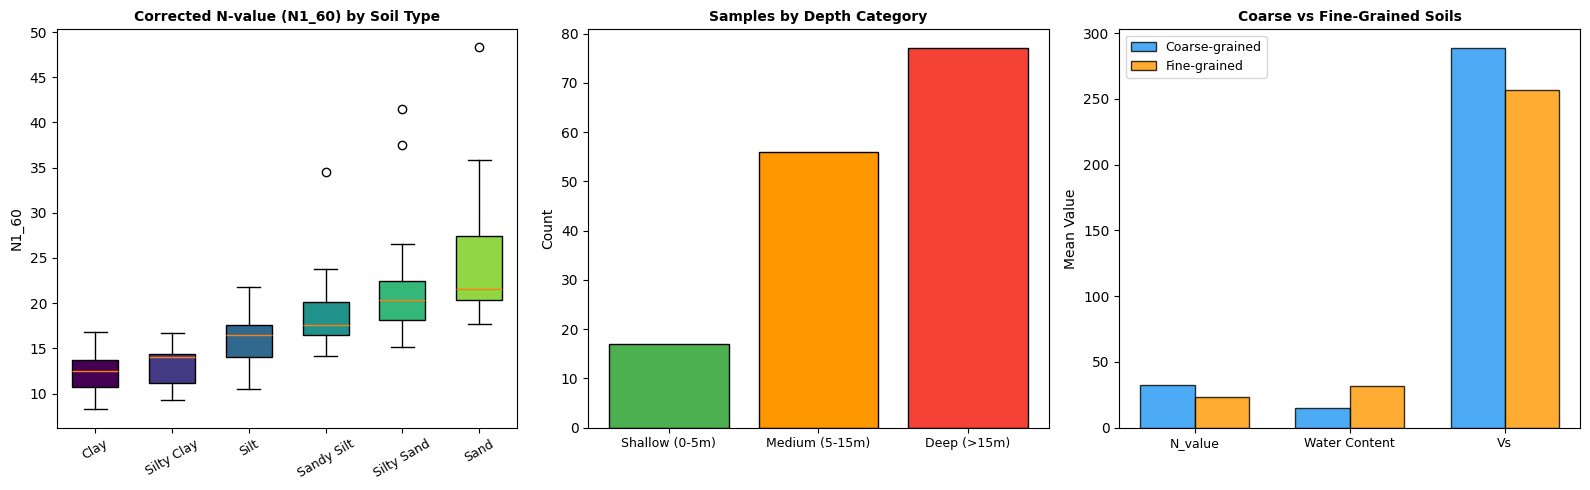

In [12]:
# ─────────────────────────────────────────────────────
# VISUALIZE ENGINEERED FEATURES
# ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# ── N1_60 by soil type ──
ax = axes[0]
soil_order = df.groupby('soil_type')['N1_60'].median().sort_values().index
for i, soil in enumerate(soil_order):
    data = df[df['soil_type'] == soil]['N1_60']
    ax.boxplot(data, positions=[i], widths=0.6, patch_artist=True,
               boxprops=dict(facecolor=plt.cm.viridis(i / len(soil_order))))
ax.set_xticks(range(len(soil_order)))
ax.set_xticklabels(soil_order, rotation=30, fontsize=9)
ax.set_ylabel('N1_60')
ax.set_title('Corrected N-value (N1_60) by Soil Type', fontweight='bold', fontsize=10)

# ── Depth category counts ──
ax = axes[1]
depth_counts = df['depth_category'].value_counts().sort_index()
ax.bar(range(len(depth_counts)), depth_counts.values,
       color=['#4CAF50', '#FF9800', '#F44336'], edgecolor='black')
ax.set_xticks(range(len(depth_counts)))
ax.set_xticklabels(depth_counts.index, fontsize=9)
ax.set_ylabel('Count')
ax.set_title('Samples by Depth Category', fontweight='bold', fontsize=10)

# ── Soil class comparison ──
ax = axes[2]
class_stats = df.groupby('soil_class')[['N_value', 'water_content', 'Vs_measured']].mean()
x = np.arange(len(class_stats.columns))
width = 0.35
ax.bar(x - width/2, class_stats.iloc[0], width, label=class_stats.index[0],
       color='#2196F3', edgecolor='black', alpha=0.8)
ax.bar(x + width/2, class_stats.iloc[1], width, label=class_stats.index[1],
       color='#FF9800', edgecolor='black', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(['N_value', 'Water Content', 'Vs'], fontsize=9)
ax.set_ylabel('Mean Value')
ax.set_title('Coarse vs Fine-Grained Soils', fontweight='bold', fontsize=10)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('engineered_features.png', dpi=100, bbox_inches='tight')
plt.show()

## Part 5: Preprocessing for ML

Now we prepare the data for machine learning: encode categoricals, scale numericals.

---

In [13]:
# ─────────────────────────────────────────────────────
# PREPROCESSING — Encode and Scale
# ─────────────────────────────────────────────────────
from sklearn.preprocessing import StandardScaler, LabelEncoder

# ── Select features for ML ──
ml_features = ['depth', 'N_value', 'water_content', 'unit_weight',
               'fines_content', 'liquid_limit', 'plasticity_index',
               'Vs_measured', 'N1_60', 'N_over_depth']

X = df[ml_features].copy()

# ── Encode soil type (target for potential classification) ──
le = LabelEncoder()
y_soil = le.fit_transform(df['soil_type'])
print("Label Encoding for soil_type:")
for i, name in enumerate(le.classes_):
    print(f"  {name:15s} -> {i}")

# ── Standard scaling ──
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"\nML-Ready Dataset:")
print(f"  Feature matrix shape: {X_scaled.shape}")
print(f"  Target (soil_type) shape: {y_soil.shape}")
print(f"  All features scaled to mean~0, std~1")
print(f"\n  Scaled means: {X_scaled.mean(axis=0).round(4)}")
print(f"  Scaled stds:  {X_scaled.std(axis=0).round(4)}")

Label Encoding for soil_type:
  Clay            -> 0
  Sand            -> 1
  Sandy Silt      -> 2
  Silt            -> 3
  Silty Clay      -> 4
  Silty Sand      -> 5

ML-Ready Dataset:
  Feature matrix shape: (150, 10)
  Target (soil_type) shape: (150,)
  All features scaled to mean~0, std~1

  Scaled means: [-0. -0. -0. -0.  0. -0. -0.  0. -0.  0.]
  Scaled stds:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Part 6: PCA — Dimensionality Reduction

With 10 features (some correlated), PCA can compress the information into fewer components.

---

PCA Explained Variance
  PC 1: 0.602 ( 60.2%)  cum: 0.602 ( 60.2%)  ##############################
  PC 2: 0.253 ( 25.3%)  cum: 0.855 ( 85.5%)  ############
  PC 3: 0.085 (  8.5%)  cum: 0.941 ( 94.1%)  #### <- 90%
  PC 4: 0.015 (  1.5%)  cum: 0.956 ( 95.6%)  
  PC 5: 0.014 (  1.4%)  cum: 0.970 ( 97.0%)  
  PC 6: 0.012 (  1.2%)  cum: 0.982 ( 98.2%)  
  PC 7: 0.009 (  0.9%)  cum: 0.991 ( 99.1%)  
  PC 8: 0.006 (  0.6%)  cum: 0.996 ( 99.6%)  
  PC 9: 0.003 (  0.3%)  cum: 0.999 ( 99.9%)  
  PC10: 0.001 (  0.1%)  cum: 1.000 (100.0%)  


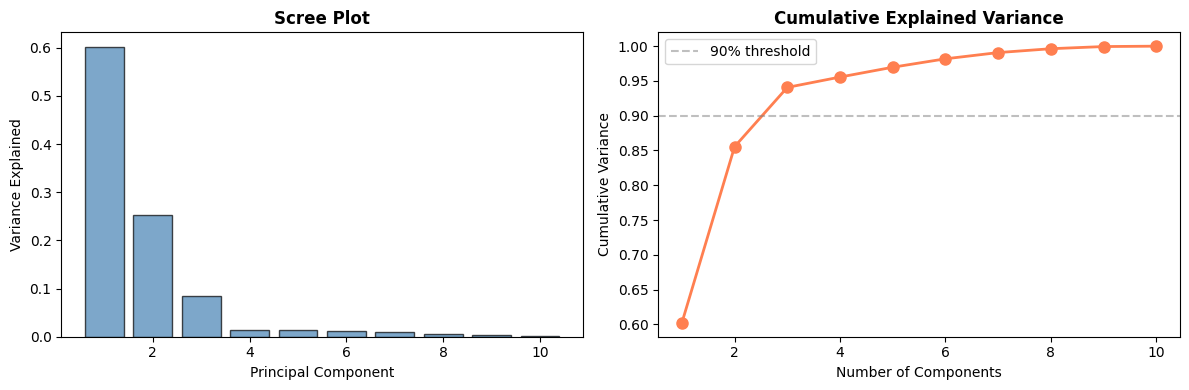

In [14]:
# ─────────────────────────────────────────────────────
# PCA — REDUCE 10 FEATURES
# ─────────────────────────────────────────────────────
from sklearn.decomposition import PCA

# ── Full PCA to analyze variance ──
pca_full = PCA()
pca_full.fit(X_scaled)

cumulative_var = np.cumsum(pca_full.explained_variance_ratio_)

print("PCA Explained Variance")
print("=" * 55)
for i, (ratio, cum) in enumerate(zip(pca_full.explained_variance_ratio_, cumulative_var)):
    bar = "#" * int(ratio * 100 / 2)
    marker = " <- 90%" if cum >= 0.9 and (i == 0 or cumulative_var[i-1] < 0.9) else ""
    print(f"  PC{i+1:2d}: {ratio:.3f} ({ratio*100:5.1f}%)  cum: {cum:.3f} ({cum*100:5.1f}%)  {bar}{marker}")

# ── Scree plot ──
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(range(1, len(pca_full.explained_variance_ratio_) + 1),
            pca_full.explained_variance_ratio_,
            color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Variance Explained')
axes[0].set_title('Scree Plot', fontweight='bold')

axes[1].plot(range(1, len(cumulative_var) + 1), cumulative_var,
             'o-', color='coral', linewidth=2, markersize=8)
axes[1].axhline(y=0.9, color='gray', linestyle='--', alpha=0.5, label='90% threshold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance')
axes[1].set_title('Cumulative Explained Variance', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('pca_scree.png', dpi=100, bbox_inches='tight')
plt.show()

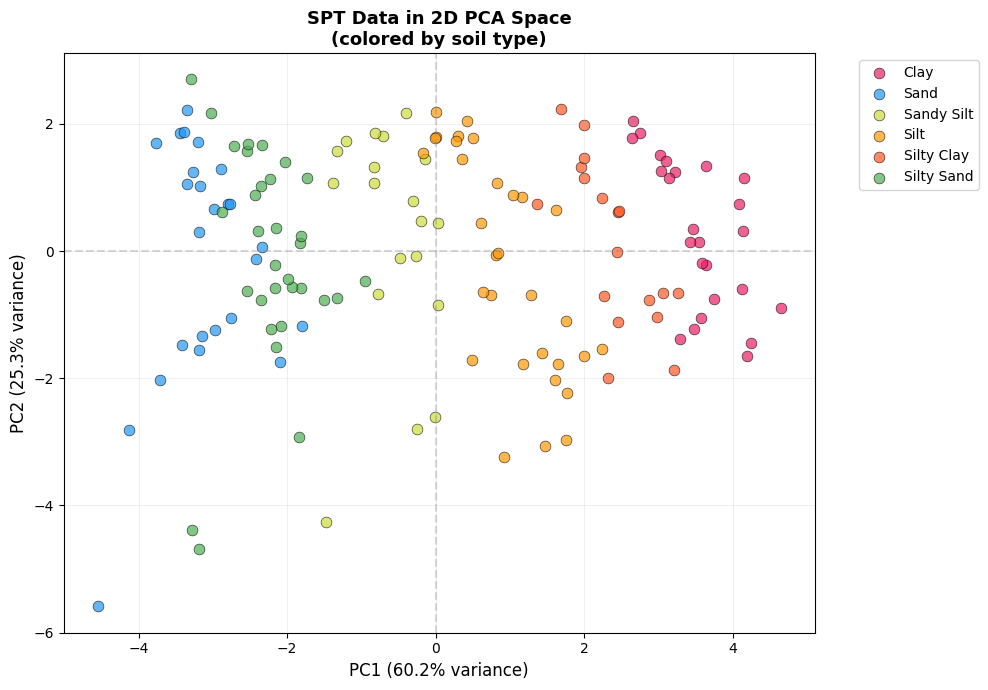

Variance retained with 2 PCs: 85.5%
Fine-grained soils (Clay, Silt) should cluster separately from coarse-grained (Sand).


In [15]:
# ─────────────────────────────────────────────────────
# PCA — 2D Visualization colored by soil type
# ─────────────────────────────────────────────────────
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(10, 7))
for soil in sorted(df['soil_type'].unique()):
    mask = df['soil_type'] == soil
    color = soil_colors.get(soil, '#999999')
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=color, label=soil, s=60, alpha=0.7,
               edgecolors='black', linewidth=0.5)

ax.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} variance)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} variance)', fontsize=12)
ax.set_title('SPT Data in 2D PCA Space\n(colored by soil type)', fontweight='bold', fontsize=13)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.axhline(0, color='gray', linestyle='--', alpha=0.3)
ax.axvline(0, color='gray', linestyle='--', alpha=0.3)
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('pca_soil_types.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"Variance retained with 2 PCs: {pca_2d.explained_variance_ratio_.sum():.1%}")
print("Fine-grained soils (Clay, Silt) should cluster separately from coarse-grained (Sand).")

## Part 7: Summary of Findings

---

In [16]:
# ─────────────────────────────────────────────────────
# PHASE 2 CAPSTONE SUMMARY
# ─────────────────────────────────────────────────────
print("=" * 60)
print("   PHASE 2 CAPSTONE — SPT Borehole EDA Summary")
print("=" * 60)
print(f"  Dataset: {df.shape[0]} samples, {df.shape[1]} features (after engineering)")
print(f"  Boreholes: {df['borehole_id'].nunique()} ({', '.join(sorted(df['borehole_id'].unique()))})")
print(f"  Soil types: {df['soil_type'].nunique()}")
print("-" * 60)
print("  Key Findings:")
print("  1. N-value increases with depth (overburden effect)")
print("  2. Strong correlation: fines <-> water content")
print("  3. Sand has highest stiffness; Clay has lowest")
print("  4. N1_60 correction normalizes for depth effects")
print("  5. PCA: first 2-3 PCs capture most of variance")
print("  6. PCA separates fine-grained from coarse-grained soils")
print("-" * 60)
print("  Skills Applied: pandas, matplotlib, seaborn, sklearn")
print("  Steps: Load -> Clean -> EDA -> Engineer -> Scale -> PCA")
print("=" * 60)

   PHASE 2 CAPSTONE — SPT Borehole EDA Summary
  Dataset: 150 samples, 18 features (after engineering)
  Boreholes: 6 (BH-01, BH-02, BH-03, BH-04, BH-05, BH-06)
  Soil types: 6
------------------------------------------------------------
  Key Findings:
  1. N-value increases with depth (overburden effect)
  2. Strong correlation: fines <-> water content
  3. Sand has highest stiffness; Clay has lowest
  4. N1_60 correction normalizes for depth effects
  5. PCA: first 2-3 PCs capture most of variance
  6. PCA separates fine-grained from coarse-grained soils
------------------------------------------------------------
  Skills Applied: pandas, matplotlib, seaborn, sklearn
  Steps: Load -> Clean -> EDA -> Engineer -> Scale -> PCA


---

## Practice Exercises

### Exercise 1: Borehole Comparison
Create a function that takes two borehole IDs and plots their SPT profiles side-by-side.
Which boreholes are most similar? Most different?

### Exercise 2: Vs Prediction Potential
Plot N-value vs Vs for each soil type separately. Fit a trend line to each.
Which soil type shows the strongest linear relationship?

### Exercise 3: Additional Feature Engineering
Create two new features: (a) the ratio Vs/N_value, and (b) a plasticity class
(non-plastic if PI=0, low if PI<15, high if PI>=15). Visualize how these relate to soil type.

---

In [17]:
# ─────────────────────────────────────────────────────
# EXERCISE 1: Borehole comparison
# ─────────────────────────────────────────────────────
# def compare_boreholes(df, bh1, bh2):
#     fig, ax = plt.subplots(figsize=(8, 6))
#     for bh, color in [(bh1, 'blue'), (bh2, 'red')]:
#         data = df[df['borehole_id'] == bh].sort_values('depth')
#         ax.plot(data['N_value'], data['depth'], 'o-', color=color, label=bh)
#     ax.invert_yaxis()
#     ax.set_xlabel('N-value')
#     ax.set_ylabel('Depth (m)')
#     ax.legend()
#     ax.set_title(f'SPT Profile: {bh1} vs {bh2}')
#     plt.show()
#
# compare_boreholes(df, 'BH-01', 'BH-04')

In [18]:
# ─────────────────────────────────────────────────────
# EXERCISE 2: Vs prediction potential
# ─────────────────────────────────────────────────────
# from scipy.stats import linregress
#
# for soil in df['soil_type'].unique():
#     data = df[df['soil_type'] == soil]
#     slope, intercept, r, p, se = linregress(data['N_value'], data['Vs_measured'])
#     print(f"{soil:15s}: Vs = {slope:.2f}*N + {intercept:.1f}  (R2 = {r**2:.3f})")

---

## Key Takeaways

1. **Always start with data inspection.** `shape`, `dtypes`, `describe()`, and `value_counts()` are your first tools. Never skip this step.

2. **Clean before analyzing.** Check for missing values, duplicates, and physically impossible values. In geotechnical data, negative N-values or unit weights outside 14-24 kN/m3 are red flags.

3. **Visualize distributions and relationships.** Histograms reveal skewness, box plots reveal outliers, scatter plots reveal correlations. Each tells a different story.

4. **Feature engineering amplifies domain knowledge.** The N1_60 correction, depth categories, and soil class features encode geotechnical understanding that raw data alone cannot capture.

5. **Preprocessing is mandatory for ML.** Standard scaling ensures all features contribute equally. Label encoding converts categories to numbers. These are not optional.

6. **PCA reveals hidden structure.** Correlated soil properties compress into a few principal components that separate soil types in reduced space.

---

## How This Connects to ML

| What We Did Today | What It Becomes in ML |
|---|---|
| Data cleaning | Ensuring model inputs are valid and complete |
| Distribution analysis | Choosing appropriate transformations |
| Correlation matrix | Feature selection — remove redundant inputs |
| Feature engineering (N1_60) | Domain-informed feature creation |
| Standard scaling | Required preprocessing for most algorithms |
| PCA visualization | Assessing whether classes are separable |
| Group statistics | Understanding class imbalance and overlap |

---

*Day 035 of 100 — Phase 2 Complete!*